Preprocessing - Read the excel file and replacing "Height" column with random numbers

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
dataSet = pd.read_excel("ABC Company.xlsx")

print("Shape:", dataSet.shape)
print("Missing values:")
print(dataSet.isnull().sum())

print("\nDuplicate rows:", dataSet.duplicated().sum())
print("\nColumn names:", dataSet.columns.tolist())

np.random.seed(10)
dataSet["Height"] = np.random.randint(150, 181, size=len(dataSet))
##display((dataSet).head())
dataSet = dataSet.drop_duplicates().copy()
dataSet.to_excel("ABC_Company_New.xlsx", index=False)
display(dataSet)

Shape: (458, 9)
Missing values:
Name         0
Team         0
Number       0
Position     0
Age          0
Height       0
Weight       0
College     84
Salary      11
dtype: int64

Duplicate rows: 0

Column names: ['Name', 'Team', 'Number', 'Position', 'Age', 'Height', 'Weight', 'College', 'Salary']


,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,159,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,179,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,154,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,165,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,150,231,NaN,5000000.0
...,...,...,...,...,...,...,...,...,...
453,Shelvin Mack,Utah Jazz,8,PG,26,170,203,Butler,2433333.0
454,Raul Neto,Utah Jazz,25,PG,24,176,179,NaN,900000.0
455,Tibor Pleiss,Utah Jazz,21,C,26,175,256,NaN,2900000.0
456,Jeff Withey,Utah Jazz,24,C,26,166,231,Kansas,947276.0


Analysis Task

1. Distribution of employees across each team and calculate
the percentage split relative to the total number of employees.

Team
New Orleans Pelicans      19
Memphis Grizzlies         18
New York Knicks           16
Milwaukee Bucks           16
Utah Jazz                 16
Boston Celtics            15
Brooklyn Nets             15
Philadelphia 76ers        15
Toronto Raptors           15
Golden State Warriors     15
Los Angeles Clippers      15
Los Angeles Lakers        15
Phoenix Suns              15
Sacramento Kings          15
Chicago Bulls             15
Cleveland Cavaliers       15
Detroit Pistons           15
Indiana Pacers            15
Dallas Mavericks          15
Houston Rockets           15
San Antonio Spurs         15
Atlanta Hawks             15
Charlotte Hornets         15
Miami Heat                15
Washington Wizards        15
Denver Nuggets            15
Oklahoma City Thunder     15
Portland Trail Blazers    15
Orlando Magic             14
Minnesota Timberwolves    14
Name: count, dtype: int64
Team
New Orleans Pelicans      4.15
Memphis Grizzlies         3.93
New York Knicks           3.49
M

,Employee Count,Percentage
Team,,
New Orleans Pelicans,19,4.15
Memphis Grizzlies,18,3.93
New York Knicks,16,3.49
Milwaukee Bucks,16,3.49
Utah Jazz,16,3.49
Boston Celtics,15,3.28
Brooklyn Nets,15,3.28
Philadelphia 76ers,15,3.28
Toronto Raptors,15,3.28


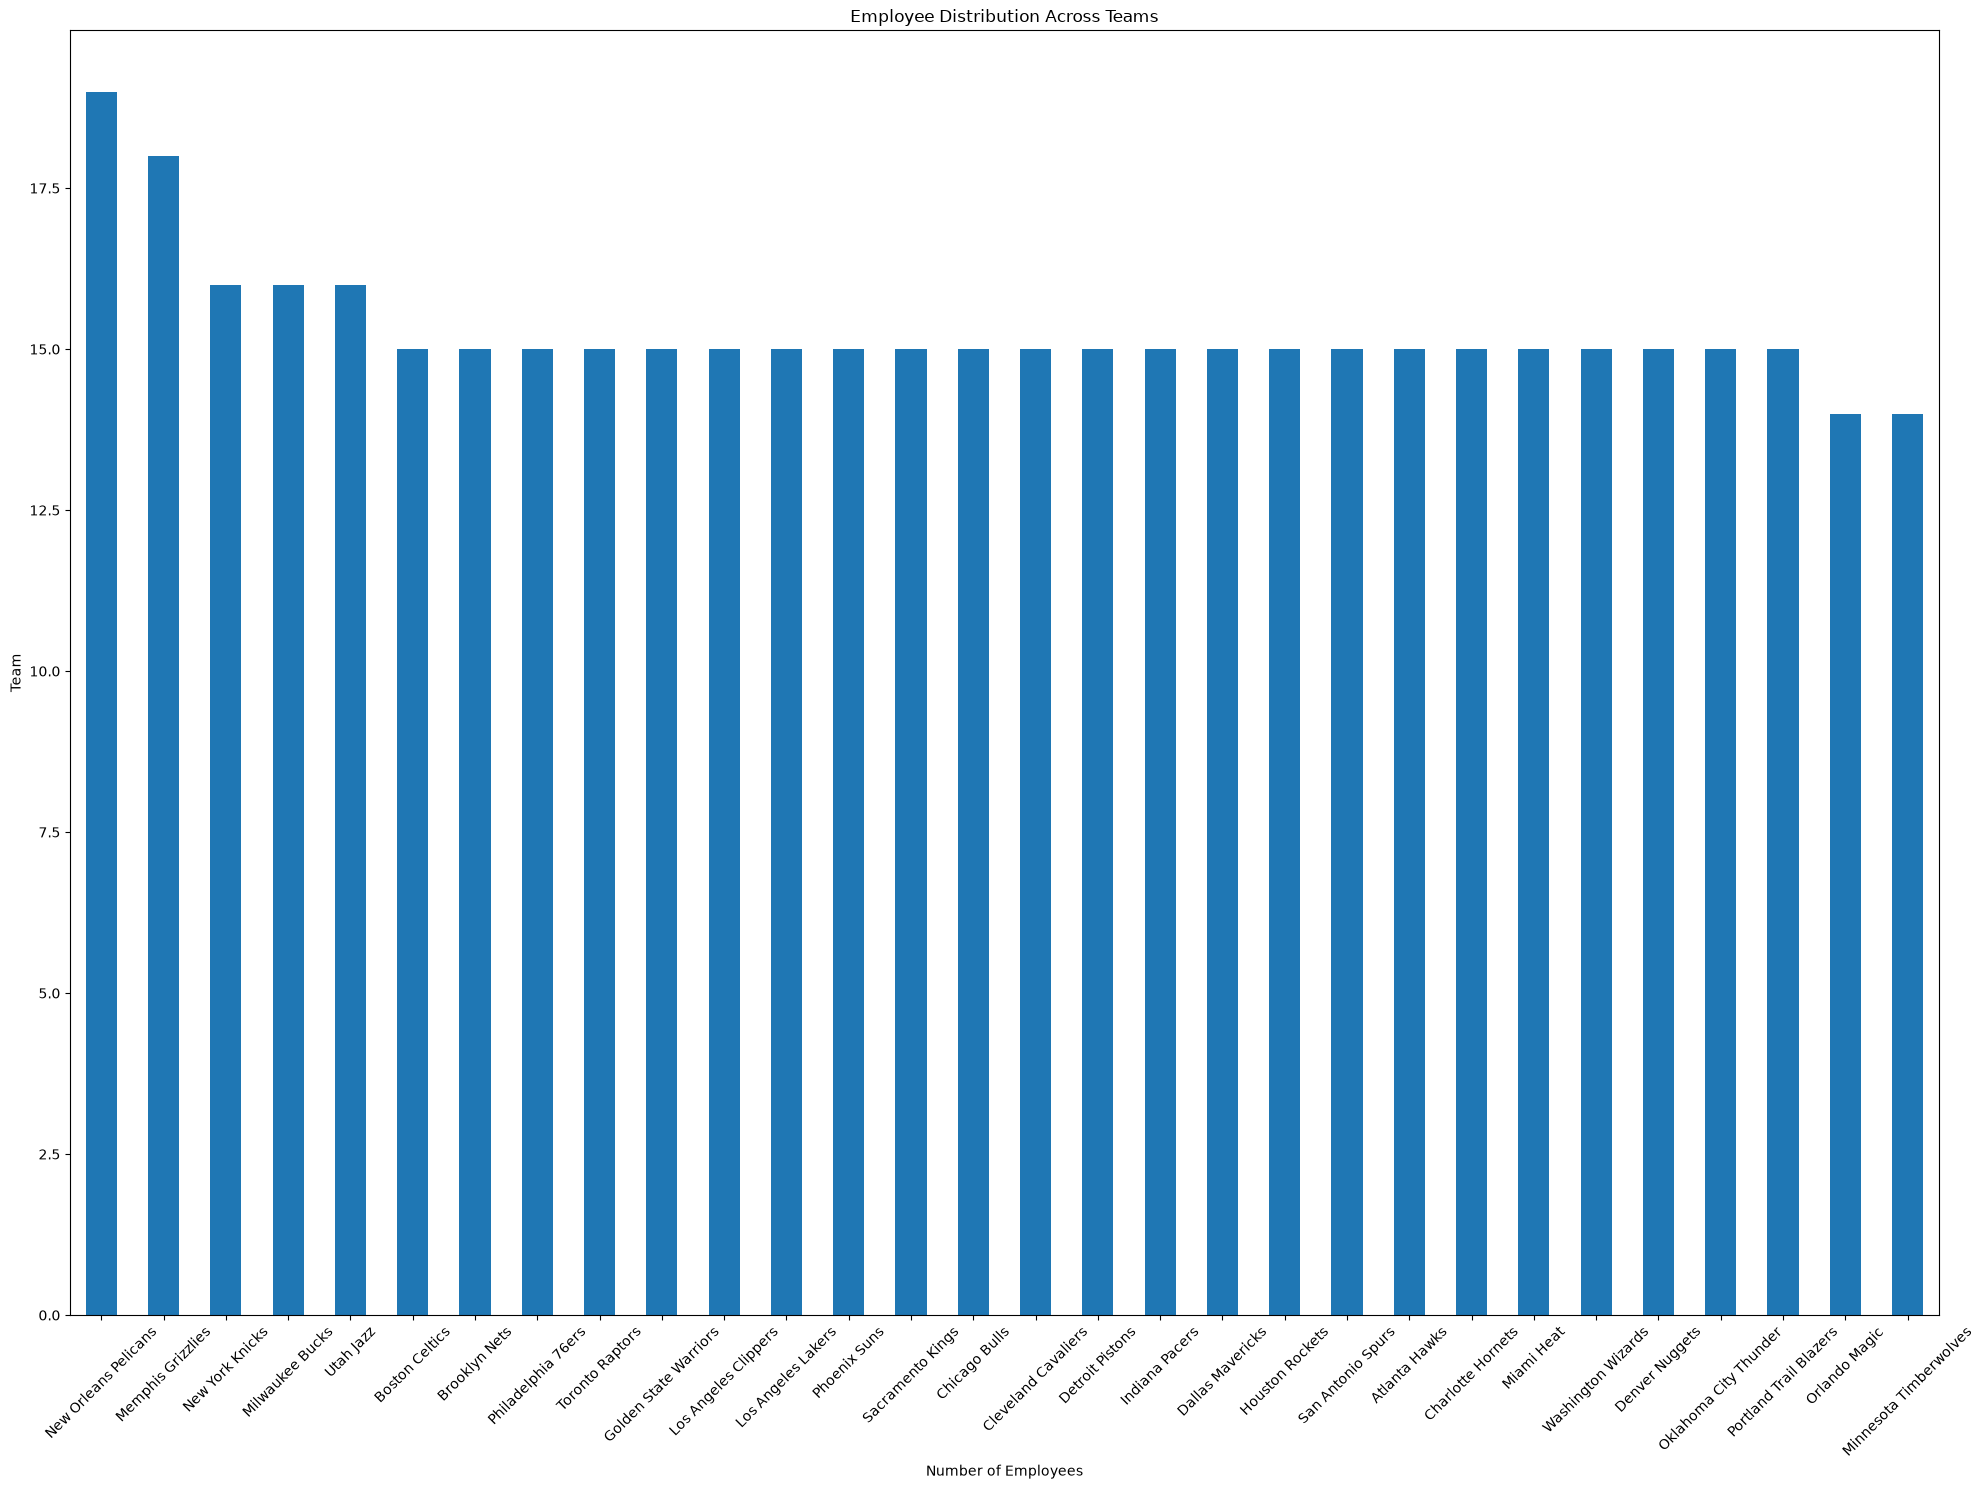

In [69]:

dataSet.to_excel("ABC_Company_New.xlsx", index=False)

team_count = dataSet["Team"].value_counts()

print(team_count)

team_percentage = (team_count / len(dataSet) * 100).round(2)

print(team_percentage)

team_table = pd.DataFrame({
    "Employee Count": team_count,
    "Percentage": team_percentage
})

display(team_table)

team_count.plot(kind="bar", figsize=(20, 15))
plt.title("Employee Distribution Across Teams")
plt.xlabel("Number of Employees")
plt.ylabel("Team")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

The team with the highest number of employees is New Orleans Pelicans, while Minnesota Timberwolves has the fewest employees.

2. Segregate employees based on their positions within the company.

Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64


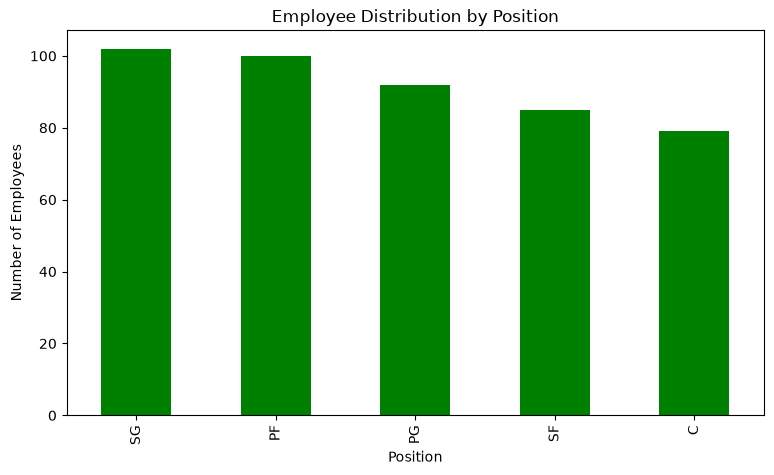

In [70]:

warnings.filterwarnings("ignore")
plt.rcParams['figure.figsize']=(10,10)

position_count = dataSet["Position"].value_counts()
print(position_count)
position_count.plot(kind="bar", figsize=(9, 5), color = "green")
plt.title("Employee Distribution by Position")
plt.xlabel("Position")
plt.ylabel("Number of Employees")
plt.show()

The most common employee position is SG , indicating that this position has the highest representation in the dataset.

3. Identify the predominant age group among employees.

Age Group
Below 20          2
20–29           334
30–39           119
40–49             3
50 and above      0
Name: count, dtype: int64


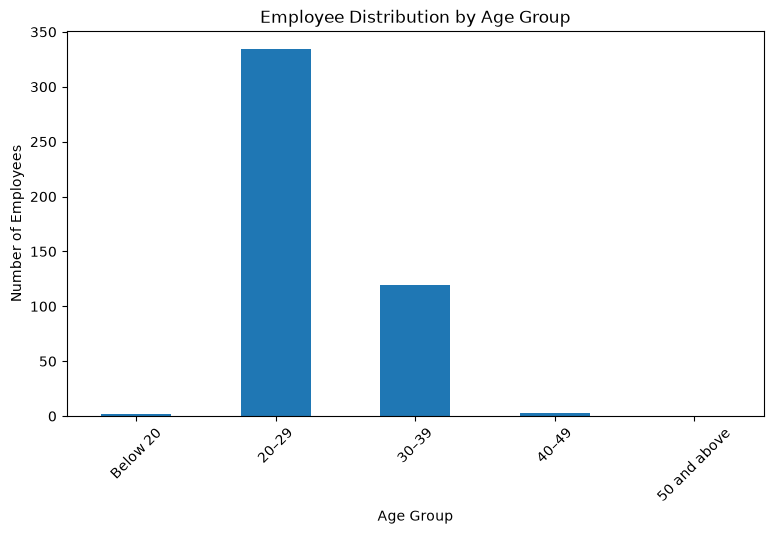

Predominant age group: 20–29
Number of employees: 334


In [42]:
age_range = [0, 20, 30, 40, 50, 100]
age_labels = [
    "Below 20", "20–29", "30–39", "40–49", "50 and above"
]

dataSet["Age Group"] = pd.cut(
    dataSet["Age"],
    bins=age_range,
    labels=age_labels,
    right=False
)

age_count = dataSet["Age Group"].value_counts(sort=False)
print(age_count)

age_count.plot(kind="bar", figsize=(9, 5))
plt.title("Employee Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)
plt.show()

print("Predominant age group:", age_count.idxmax())
print("Number of employees:", age_count.max())

The predominant age group is 20–29, meaning most employees belong to this age range.

4. Discover which team and position have the highest salary expenditure.


Salary expenditure by team: Team
Atlanta Hawks              72902950.0
Boston Celtics             58541068.0
Brooklyn Nets              52528475.0
Charlotte Hornets          78340920.0
Chicago Bulls              86783378.0
Cleveland Cavaliers       106988689.0
Dallas Mavericks           71198732.0
Denver Nuggets             60121930.0
Detroit Pistons            67168263.0
Golden State Warriors      88868997.0
Houston Rockets            75283021.0
Indiana Pacers             66751826.0
Los Angeles Clippers       94854640.0
Los Angeles Lakers         71770431.0
Memphis Grizzlies          76550880.0
Miami Heat                 82515673.0
Milwaukee Bucks            69603517.0
Minnesota Timberwolves     59709697.0
New Orleans Pelicans       82750774.0
New York Knicks            73303898.0
Oklahoma City Thunder      93765298.0
Orlando Magic              60161470.0
Philadelphia 76ers         30992894.0
Phoenix Suns               63445135.0
Portland Trail Blazers     48301818.0
Sacramento Kings

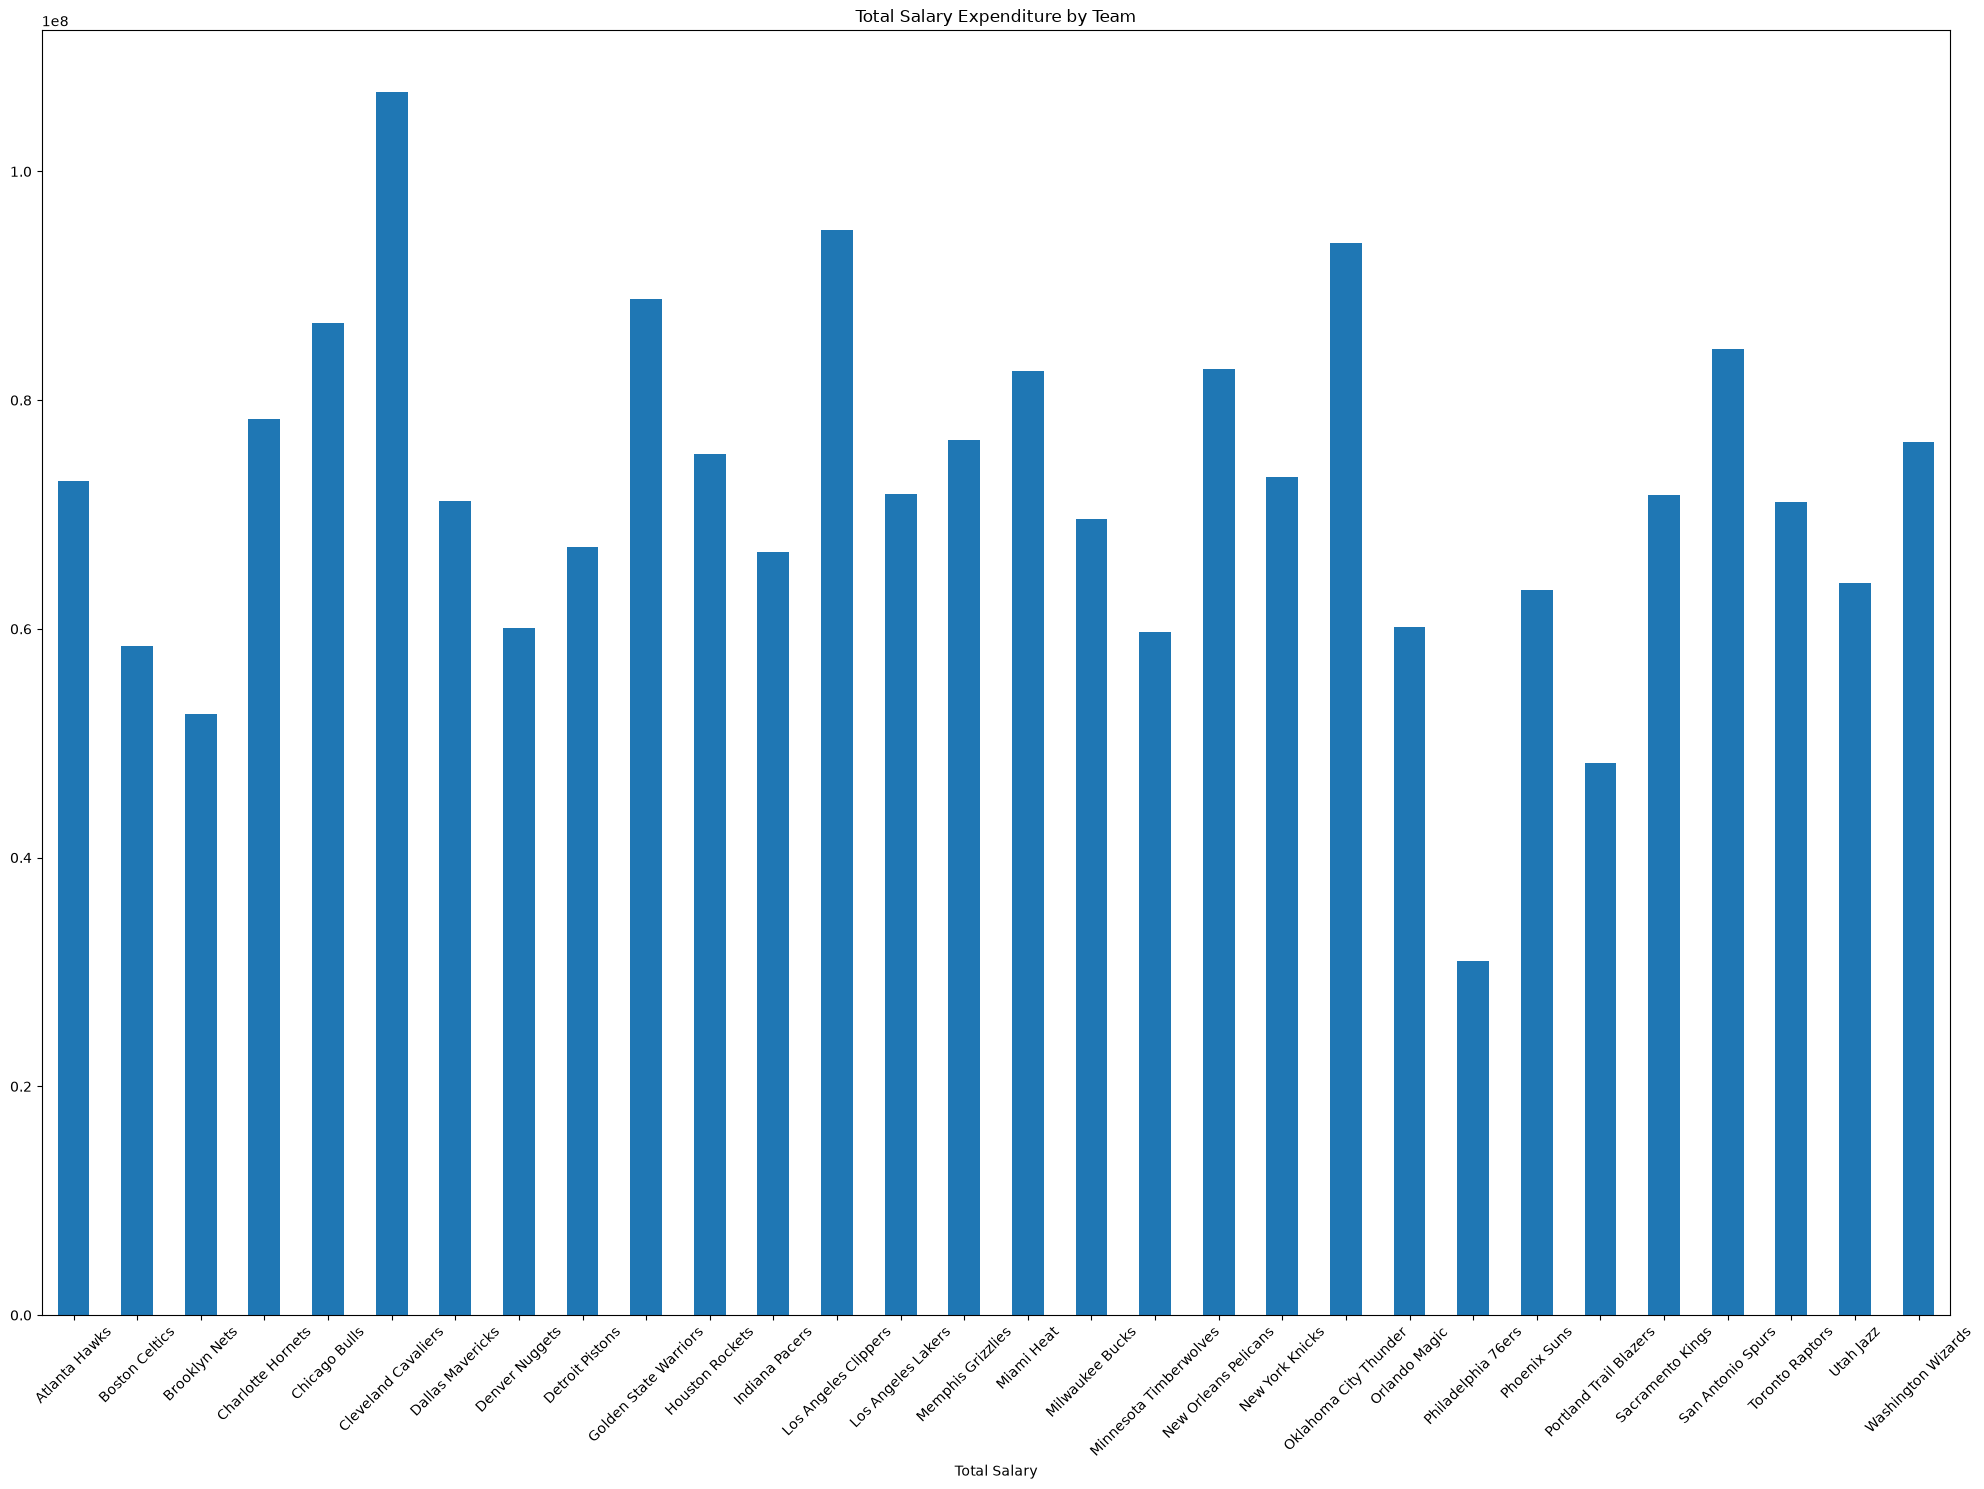

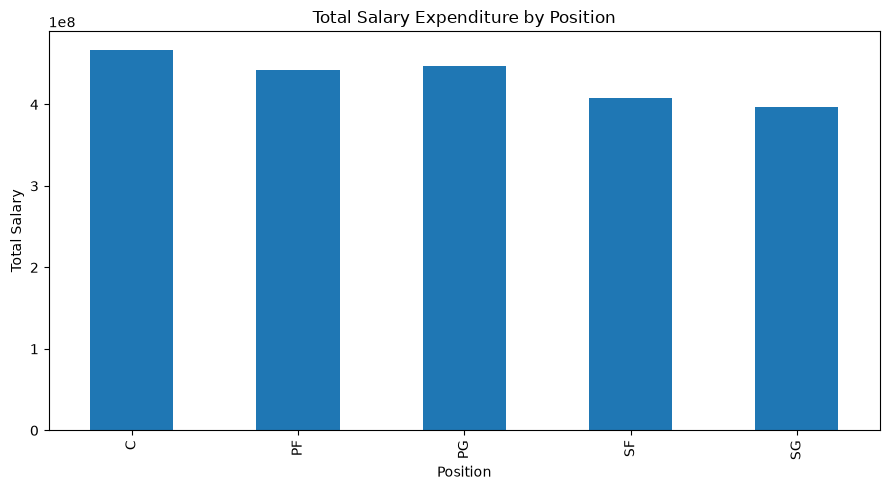

In [53]:
team_salary = dataSet.groupby("Team")["Salary"].sum()
position_salary = dataSet.groupby("Position")["Salary"].sum()

print("\nSalary expenditure by team:",team_salary )

print("\nSalary expenditure by position:",position_salary)

print("Highest_spending team:", team_salary.idxmax())
print("Total:", team_salary.max())

print("Highest_spending position:", position_salary.idxmax())
print("Total:", position_salary.max())

team_salary.plot(kind="bar", figsize=(20, 15))
plt.title("Total Salary Expenditure by Team")
plt.xlabel("Total Salary")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

position_salary.plot(kind="bar", figsize=(9, 5))
plt.title("Total Salary Expenditure by Position")
plt.xlabel("Position")
plt.ylabel("Total Salary")
plt.tight_layout()

Team "C" has the highest total salary expenditure, while "SG" has the lowest.

5. Investigate if there's any correlation between age and salary, and
represent it visually.

Correlation between Age and Salary: 0.214


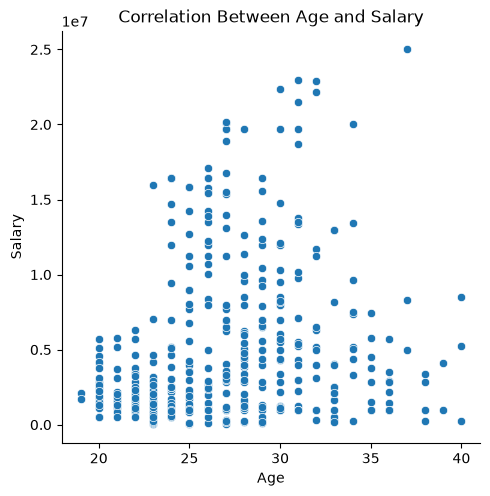

In [66]:
salary_data = dataSet[["Age", "Salary"]].dropna()

correlation = salary_data["Age"].corr(salary_data["Salary"])
print("Correlation between Age and Salary:", round(correlation, 3))

sns.relplot(data=salary_data, x="Age", y="Salary", kind = "scatter")

plt.title("Correlation Between Age and Salary")
plt.xlabel("Age")
plt.ylabel("Salary")

plt.show()


The correlation between age and salary is 0.214. This indicates a weak positive linear relationship between age and salary.